# Model Comparison

Combines the baseline and the four models (run the five notebooks first so the `results_*.csv` files exist).

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd, matplotlib.pyplot as plt
import os

base_path = "/content/drive/MyDrive/Y3S1/Assignment/Models"
files = ["results_baseline.csv", "results_01_logistic_regression.csv", "results_02_random_forest.csv",
         "results_03_decision_tree.csv", "results_04_xgboost.csv"]

# Create full paths to the files
full_paths = [os.path.join(base_path, f) for f in files]

all_results = pd.concat([pd.read_csv(f) for f in full_paths], ignore_index=True)
all_results

,model,features,accuracy,macro_F1,weighted_F1,log_loss,draw_recall
0,Baseline: always Home win,No odds,0.4440,0.2050,0.2730,20.0405,0.0000
1,Baseline: random by class share,No odds,0.3500,0.3270,0.3476,23.4276,0.2651
2,Baseline: always Home win,With odds,0.4460,0.2056,0.2752,19.9670,0.0000
3,Baseline: random by class share,With odds,0.3617,0.3374,0.3593,23.0074,0.2709
4,Reference: bookmaker favourite,With odds,0.5269,0.3870,0.4443,NaN,0.0000
5,Logistic Regression,No odds,0.4596,0.4224,0.4509,1.0481,0.2023
6,Logistic Regression,With odds,0.4965,0.4778,0.5020,0.9999,0.3431
7,Random Forest,No odds,0.4443,0.4283,0.4485,1.0459,0.3073
8,Random Forest,With odds,0.4903,0.4783,0.4992,1.0017,0.3873
9,Decision Tree,No odds,0.4475,0.4270,0.4502,1.0535,0.2933


## No-odds experiment (all 6,651 test matches)

In [ ]:
no_odds = all_results[all_results.features == "No odds"].sort_values("macro_F1", ascending=False).reset_index(drop=True)
no_odds

,model,features,accuracy,macro_F1,weighted_F1,log_loss,draw_recall
0,XGBoost,No odds,0.4455,0.4295,0.4500,1.0451,0.3091
1,Random Forest,No odds,0.4443,0.4283,0.4485,1.0459,0.3073
2,Decision Tree,No odds,0.4475,0.4270,0.4502,1.0535,0.2933
3,Logistic Regression,No odds,0.4596,0.4224,0.4509,1.0481,0.2023
4,Baseline: random by class share,No odds,0.3500,0.3270,0.3476,23.4276,0.2651
5,Baseline: always Home win,No odds,0.4440,0.2050,0.2730,20.0405,0.0000


## With-odds experiment (5,809 test matches that have odds)

In [ ]:
with_odds = all_results[all_results.features == "With odds"].sort_values("macro_F1", ascending=False).reset_index(drop=True)
with_odds

,model,features,accuracy,macro_F1,weighted_F1,log_loss,draw_recall
0,Random Forest,With odds,0.4903,0.4783,0.4992,1.0017,0.3873
1,Logistic Regression,With odds,0.4965,0.4778,0.5020,0.9999,0.3431
2,XGBoost,With odds,0.4923,0.4756,0.4984,0.9999,0.3465
3,Decision Tree,With odds,0.4834,0.4705,0.4914,1.0036,0.3608
4,Reference: bookmaker favourite,With odds,0.5269,0.3870,0.4443,NaN,0.0000
5,Baseline: random by class share,With odds,0.3617,0.3374,0.3593,23.0074,0.2709
6,Baseline: always Home win,With odds,0.4460,0.2056,0.2752,19.9670,0.0000


## Chart

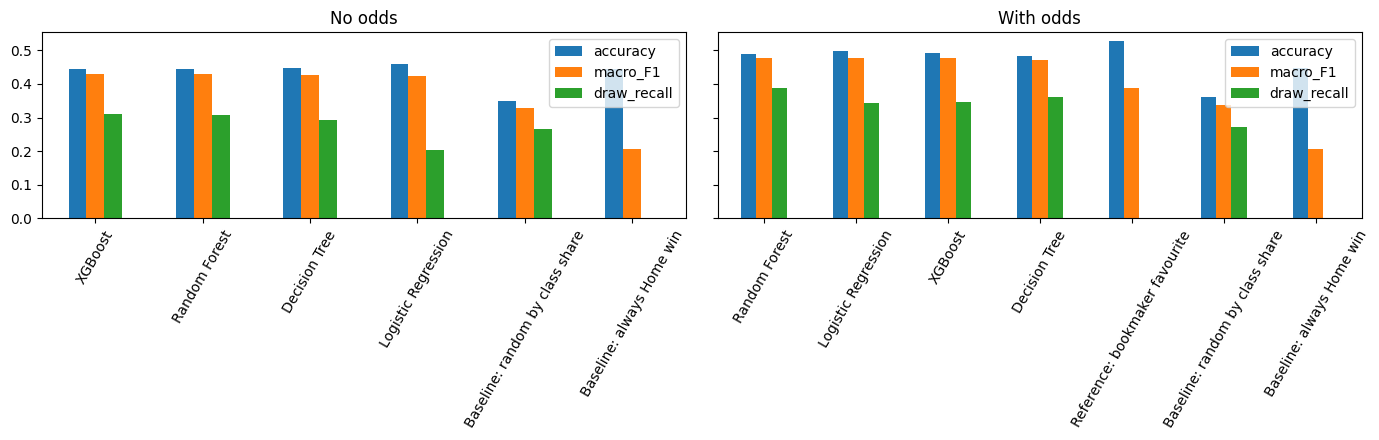

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (title, d) in zip(axes, [("No odds", no_odds), ("With odds", with_odds)]):
    d.set_index("model")[["accuracy", "macro_F1", "draw_recall"]].plot(kind="bar", ax=ax, title=title)
    ax.set_xlabel(""); ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

## Best model

In [ ]:
for name, d in [("No odds", no_odds), ("With odds", with_odds)]:
    models = d[~d.model.str.startswith(("Baseline", "Reference"))]
    best = models.iloc[0]
    print(f"{name}: best model by macro F1 = {best.model} (accuracy {best.accuracy}, macro F1 {best.macro_F1}, draw recall {best.draw_recall})")

No odds: best model by macro F1 = XGBoost (accuracy 0.4455, macro F1 0.4295, draw recall 0.3091)
With odds: best model by macro F1 = Random Forest (accuracy 0.4903, macro F1 0.4783, draw recall 0.3873)
